In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

import warnings
warnings.filterwarnings("ignore")

### Exploring Accounts table

In [ ]:
accounts = pd.read_csv("C:\\PROJECTS\\Financial_Operations_analytics\\Data\\Processed\\accounts_cleaned.csv",parse_dates=["signup_date"])

: 

In [ ]:
accounts.dtypes

account_id                 object
account_name               object
industry                   object
country                    object
signup_date        datetime64[ns]
referral_source            object
plan_tier                  object
seats                       int64
is_trial                     bool
churn_flag                   bool
dtype: object

: 

In [ ]:
accounts.isnull().sum()

account_id         0
account_name       0
industry           0
country            0
signup_date        0
referral_source    0
plan_tier          0
seats              0
is_trial           0
churn_flag         0
dtype: int64

: 

In [ ]:
accounts.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
account_id,500,500,A-2e4581,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_name,500,500,Company_0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,500,5,DevTools,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,500,7,US,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,500,NaN,NaN,NaN,2024-01-27 06:34:33.600000256,2023-01-02 00:00:00,2023-08-06 18:00:00,2024-02-21 00:00:00,2024-08-04 06:00:00,2024-12-31 00:00:00,NaN
referral_source,500,5,organic,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_tier,500,3,Pro,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seats,500.0,NaN,NaN,NaN,20.56,1.0,5.0,15.0,28.0,163.0,21.044718
is_trial,500,2,False,403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churn_flag,500,2,False,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN


: 

In [ ]:
accounts.nunique()

account_id         500
account_name       500
industry             5
country              7
signup_date        370
referral_source      5
plan_tier            3
seats               73
is_trial             2
churn_flag           2
dtype: int64

: 

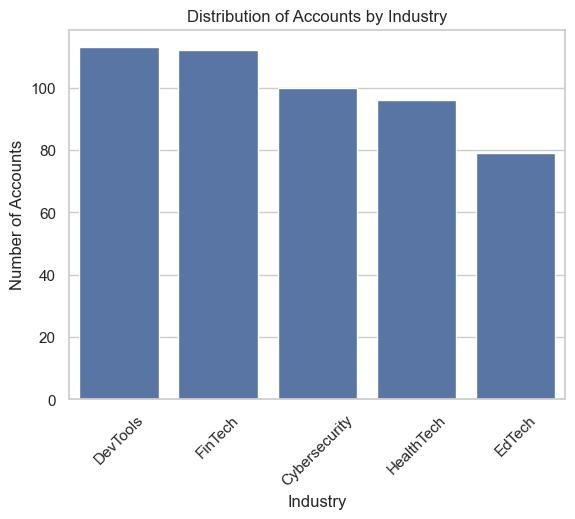

: 

In [ ]:
sns.countplot(data=accounts, x="industry", order=accounts["industry"].value_counts().index)
plt.title("Distribution of Accounts by Industry")
plt.xlabel("Industry")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=45)
plt.show()

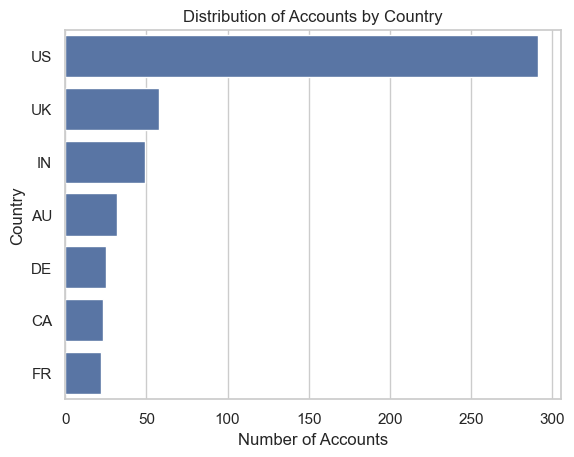

: 

In [ ]:
sns.countplot(data=accounts, y="country", order=accounts["country"].value_counts().index)
plt.title("Distribution of Accounts by Country")
plt.xlabel("Number of Accounts")
plt.ylabel("Country")
plt.show()

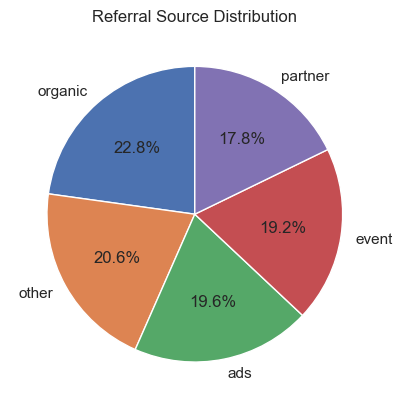

: 

: 

: 

In [ ]:
accounts["referral_source"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Referral Source Distribution")
plt.ylabel("")
plt.show()

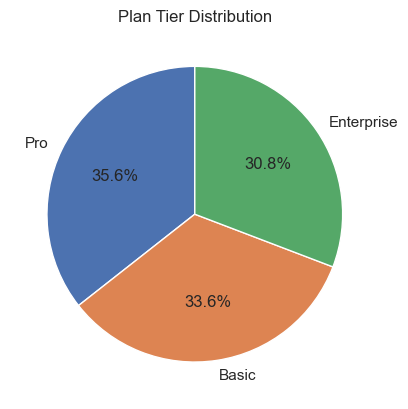

: 

In [ ]:
accounts["plan_tier"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Plan Tier Distribution")
plt.ylabel("")
plt.show()

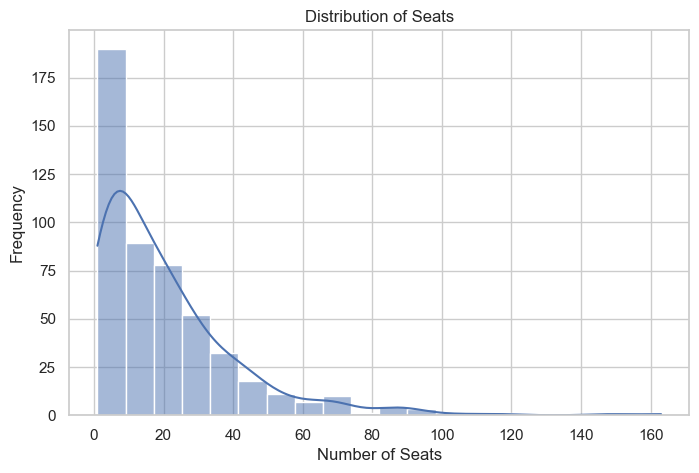

: 

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(accounts['seats'],bins = 20 ,kde=True)
plt.title("Distribution of Seats")
plt.xlabel("Number of Seats")
plt.ylabel("Frequency")
plt.show()

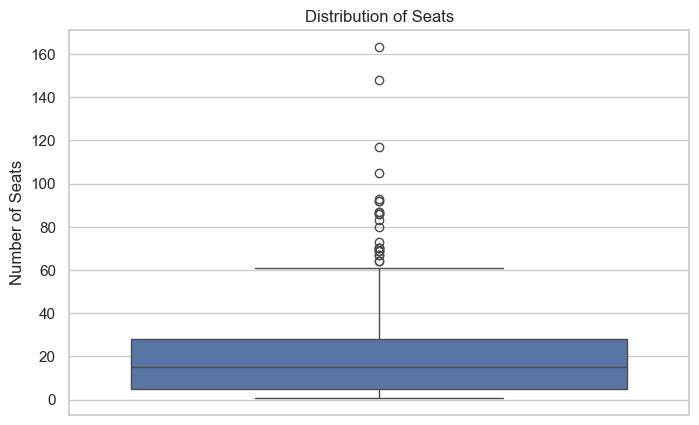

: 

: 

: 

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(y=accounts['seats'])
plt.title("Distribution of Seats")
plt.ylabel("Number of Seats")
plt.show()

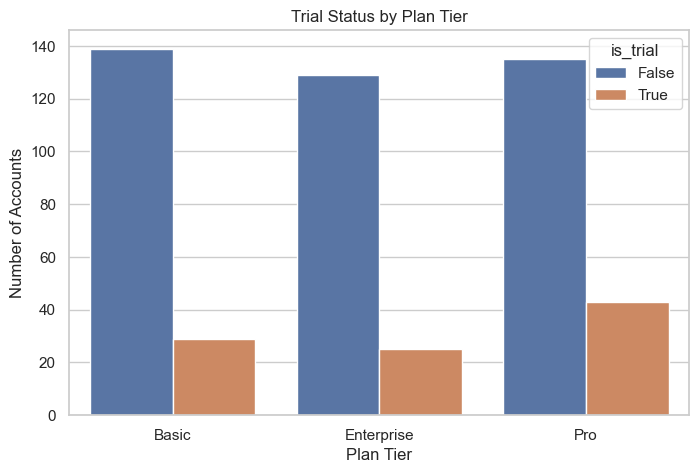

: 

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=accounts,x="plan_tier",hue="is_trial")
plt.title("Trial Status by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Number of Accounts")
plt.show()

In [ ]:
accounts["is_trial"] = accounts["is_trial"].replace({
    False: "Non-Trial",
    True: "Trial"
})

: 

: 

: 

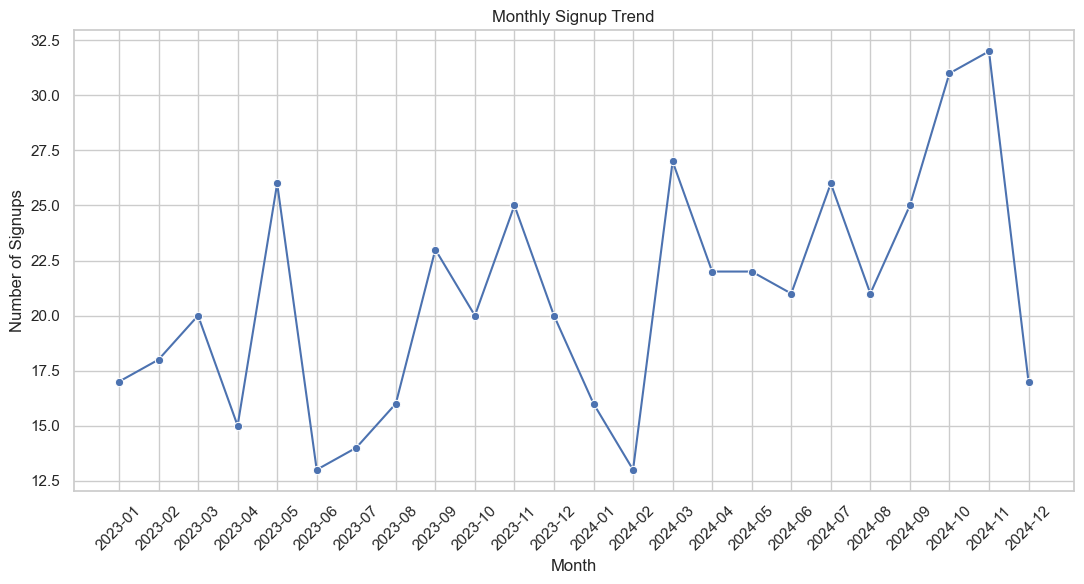

: 

In [ ]:
monthly_signup = (accounts.groupby(accounts["signup_date"].dt.to_period("M")).size())
monthly_signup.index = monthly_signup.index.astype(str)
plt.figure(figsize=(11,6))

sns.lineplot(
    x=monthly_signup.index,
    y=monthly_signup.values,
    marker="o"
)

plt.title("Monthly Signup Trend")
plt.xlabel("Month")
plt.ylabel("Number of Signups")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Explore Churn table

In [2]:
churn = pd.read_csv("C:\\PROJECTS\\Financial_Operations_analytics\\Data\\Processed\\churn_cleaned.csv",parse_dates=["churn_date"])

In [3]:
churn.dtypes

churn_event_id                      object
account_id                          object
churn_date                  datetime64[ns]
reason_code                         object
refund_amount_usd                  float64
preceding_upgrade_flag                bool
preceding_downgrade_flag              bool
is_reactivation                       bool
feedback_text                       object
dtype: object

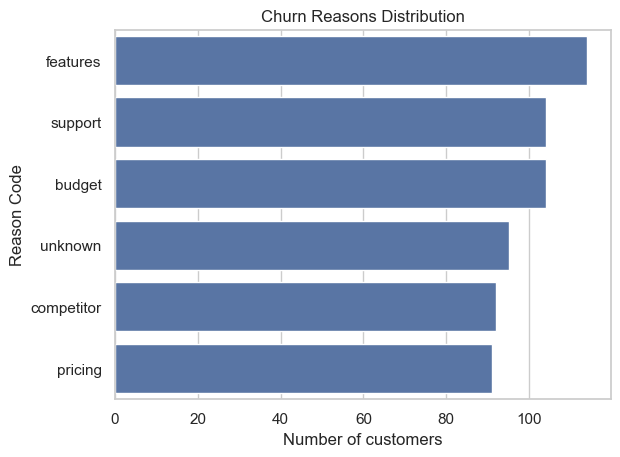

In [4]:
plt.Figure(figsize=(8,5))
sns.countplot(
    data=churn,
    y="reason_code",
    order=churn["reason_code"].value_counts().index)

plt.title("Churn Reasons Distribution")
plt.xlabel("Number of customers")
plt.ylabel("Reason Code")
plt.show()

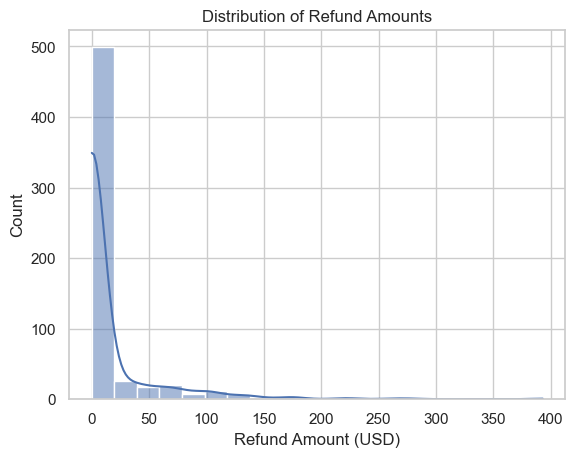

: 

In [ ]:
sns.histplot(churn["refund_amount_usd"], bins=20, kde=True)
plt.title("Distribution of Refund Amounts")
plt.xlabel("Refund Amount (USD)")
plt.show()

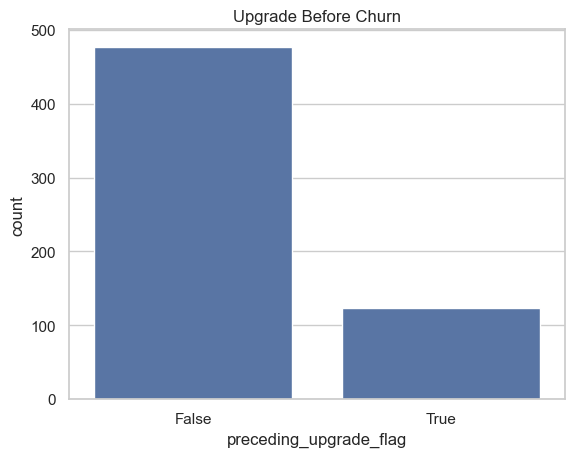

: 

: 

: 

In [ ]:
sns.countplot(data=churn, x="preceding_upgrade_flag")
plt.title("Upgrade Before Churn")
plt.show()

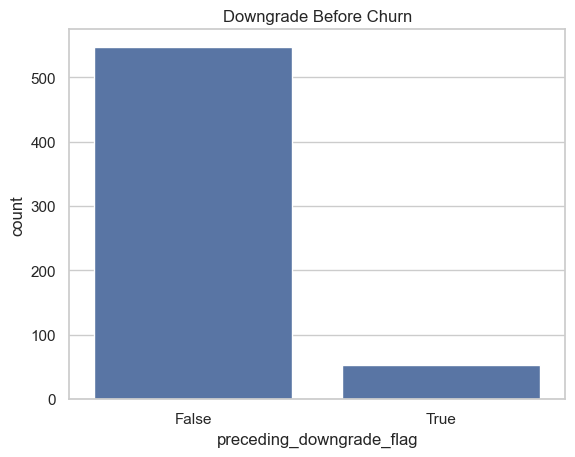

In [5]:
sns.countplot(data=churn, x="preceding_downgrade_flag")
plt.title("Downgrade Before Churn")
plt.show()

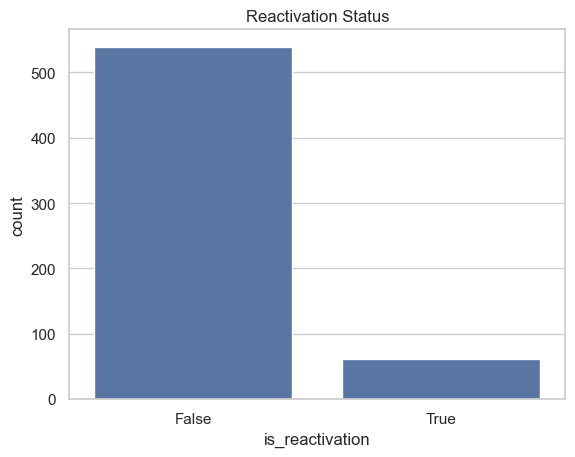

In [6]:
sns.countplot(data=churn, x="is_reactivation")
plt.title("Reactivation Status")
plt.show()

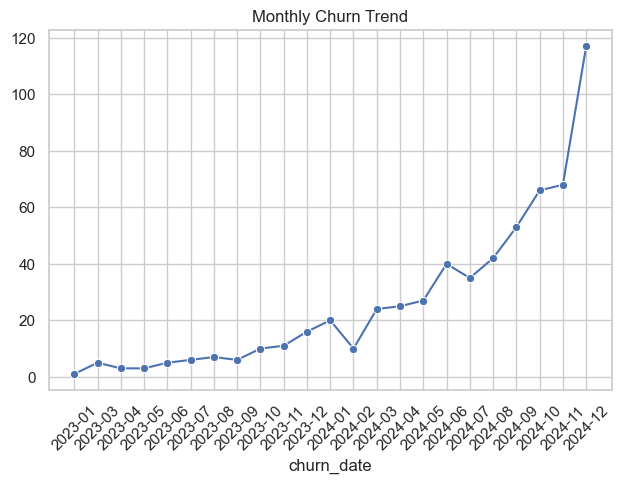

In [7]:
monthly = churn.groupby(churn["churn_date"].dt.to_period("M")).size()
monthly.index = monthly.index.astype(str)

sns.lineplot(
    x=monthly.index,
    y=monthly.values,
    marker="o"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.title("Monthly Churn Trend")
plt.show()

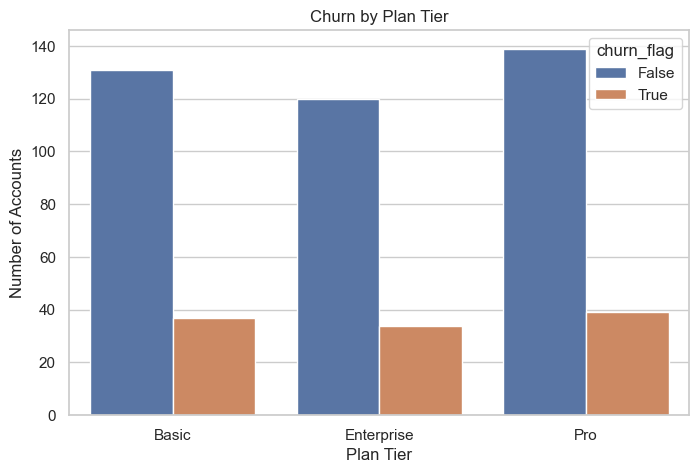

: 

: 

: 

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=accounts,
    x="plan_tier",
    hue="churn_flag"
)

plt.title("Churn by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Number of Accounts")

plt.show()

### Explore Feature_usage Dataset


In [8]:
feature_usage = pd.read_csv(r'C:\PROJECTS\Financial_Operations_analytics\Data\Processed\feature_usage_cleaned.csv',parse_dates=["usage_date"])

In [9]:
feature_usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   usage_id             25000 non-null  object        
 1   subscription_id      25000 non-null  object        
 2   usage_date           25000 non-null  datetime64[ns]
 3   feature_name         25000 non-null  object        
 4   usage_count          25000 non-null  int64         
 5   usage_duration_secs  25000 non-null  int64         
 6   error_count          25000 non-null  int64         
 7   is_beta_feature      25000 non-null  bool          
dtypes: bool(1), datetime64[ns](1), int64(3), object(3)
memory usage: 1.4+ MB


In [10]:
feature_usage["feature_name"].nunique()

40

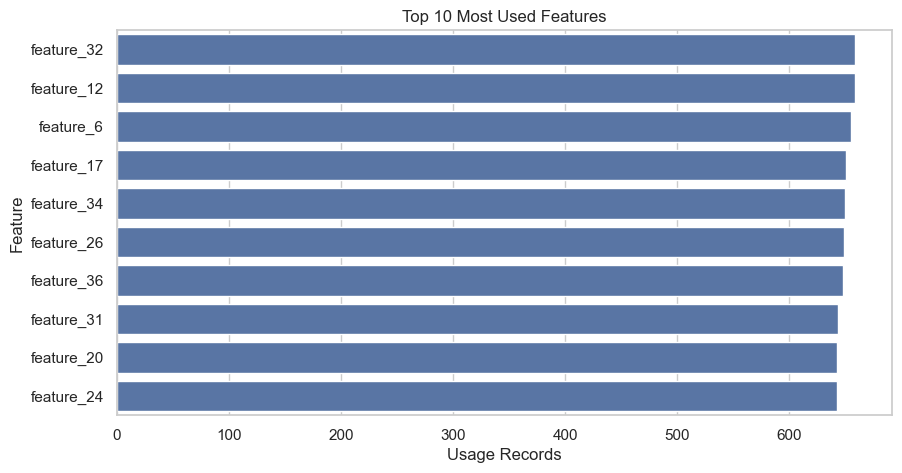

In [11]:
top_features = feature_usage["feature_name"].value_counts().head(10)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title("Top 10 Most Used Features")
plt.xlabel("Usage Records")
plt.ylabel("Feature")

plt.show()

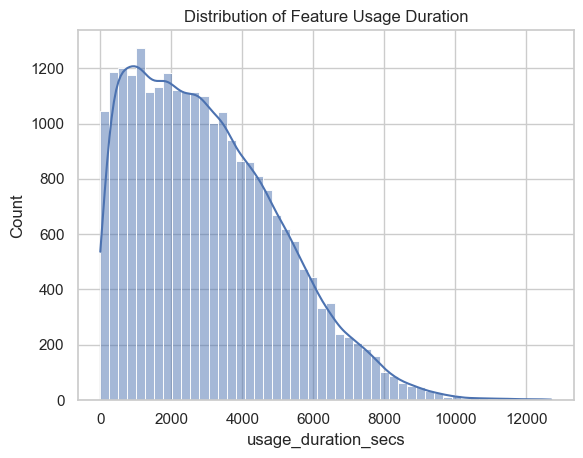

: 

In [ ]:
sns.histplot(
    data =feature_usage,
    x="usage_duration_secs",
    bins=50,
    kde = True)
plt.title("Distribution of Feature Usage Duration")
plt.show()

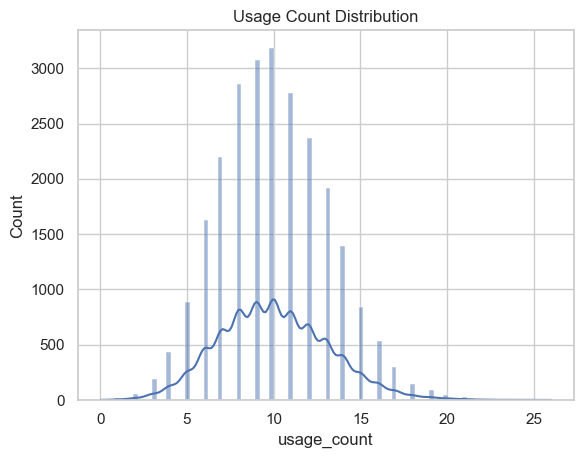

In [12]:
sns.histplot(feature_usage["usage_count"], kde=True)

plt.title("Usage Count Distribution")
plt.show()

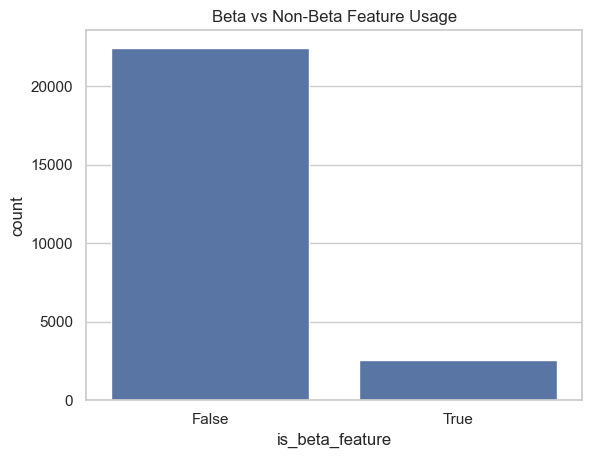

: 

In [ ]:
sns.countplot(data=feature_usage, x="is_beta_feature")

plt.title("Beta vs Non-Beta Feature Usage")
plt.show()

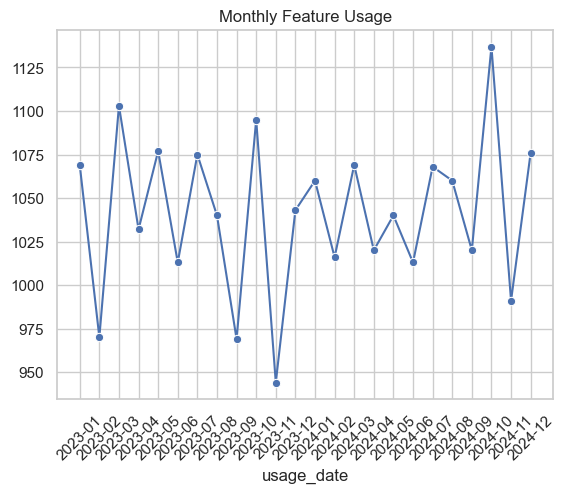

: 

In [ ]:
monthly = feature_usage.groupby(
    feature_usage["usage_date"].dt.to_period("M")
).size()

monthly.index = monthly.index.astype(str)

sns.lineplot(
    x=monthly.index,
    y=monthly.values,
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Monthly Feature Usage")
plt.show()

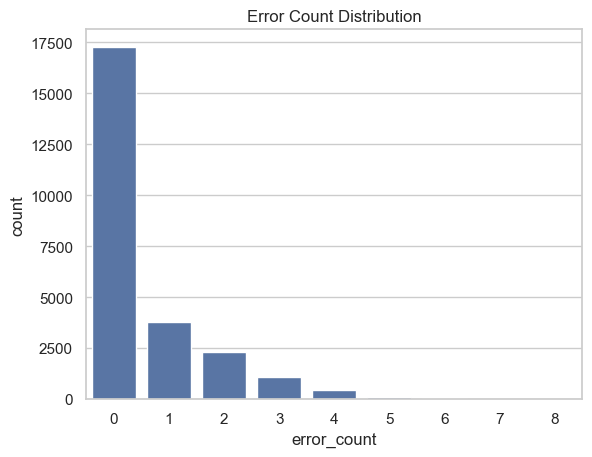

In [13]:
sns.countplot(data = feature_usage,
              x = "error_count"
              )
plt.title("Error Count Distribution")
plt.show()

### Explore Subscriptions Table

In [14]:
subscriptions = pd.read_csv(r'C:\PROJECTS\Financial_Operations_analytics\Data\Processed\subscriptions_cleaned.csv',parse_dates=["start_date","end_date"]  )
subscriptions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   subscription_id    5000 non-null   object        
 1   account_id         5000 non-null   object        
 2   start_date         5000 non-null   datetime64[ns]
 3   end_date           486 non-null    datetime64[ns]
 4   plan_tier          5000 non-null   object        
 5   seats              5000 non-null   int64         
 6   mrr_amount         5000 non-null   int64         
 7   arr_amount         5000 non-null   int64         
 8   is_trial           5000 non-null   bool          
 9   upgrade_flag       5000 non-null   bool          
 10  downgrade_flag     5000 non-null   bool          
 11  churn_flag         5000 non-null   bool          
 12  billing_frequency  5000 non-null   object        
 13  auto_renew_flag    5000 non-null   bool          
 14  is_activ

Text(0.5, 0, 'Plan Tier')

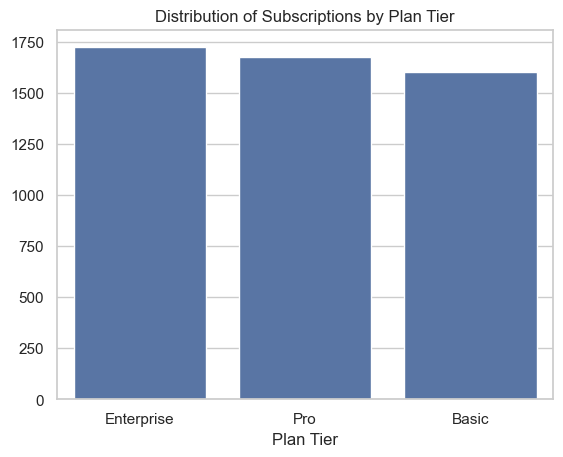

In [15]:
sns.barplot(
    x=subscriptions["plan_tier"].value_counts().index,
    y=subscriptions["plan_tier"].value_counts().values
)
plt.title("Distribution of Subscriptions by Plan Tier")
plt.xlabel("Plan Tier") 

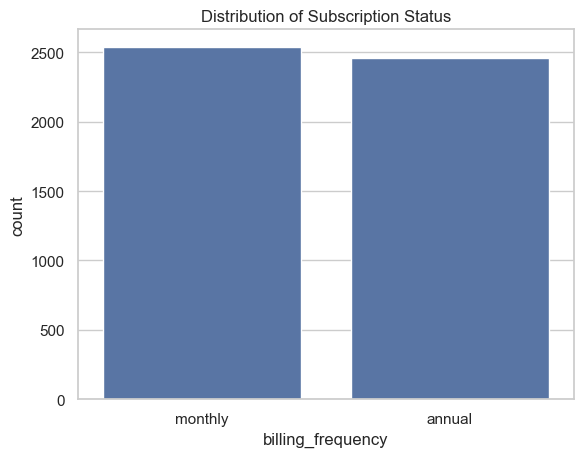

In [16]:
sns.countplot(data = subscriptions,
              x = "billing_frequency"
              )
plt.title("Distribution of Subscription Status")
plt.show()

Text(0.5, 1.0, 'Distribution of Monthly Recurring Revenue')

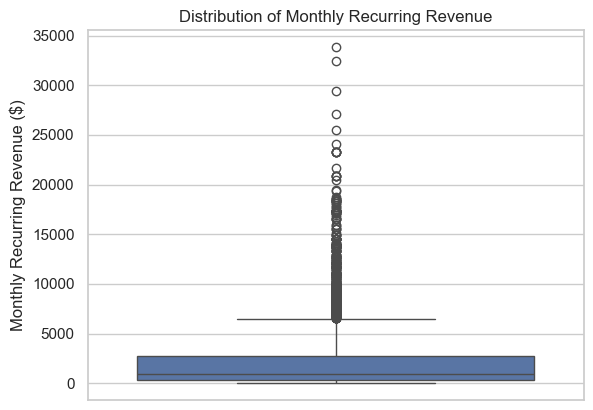

In [18]:

sns.boxplot(y=subscriptions["mrr_amount"])
plt.ylabel("Monthly Recurring Revenue ($)")
plt.title("Distribution of Monthly Recurring Revenue")



Text(0.5, 1.0, 'Distribution of Annual Recurring Revenue')

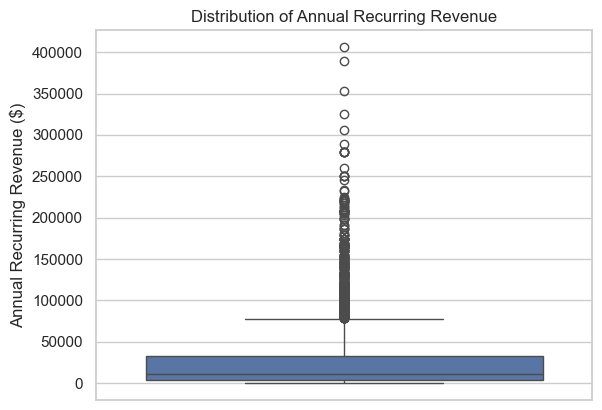

In [20]:

sns.boxplot(y=subscriptions["arr_amount"])
plt.ylabel("Annual Recurring Revenue ($)")
plt.title("Distribution of Annual Recurring Revenue")


Text(0.5, 1.0, 'Monthly Recurring Revenue by Plan Tier')

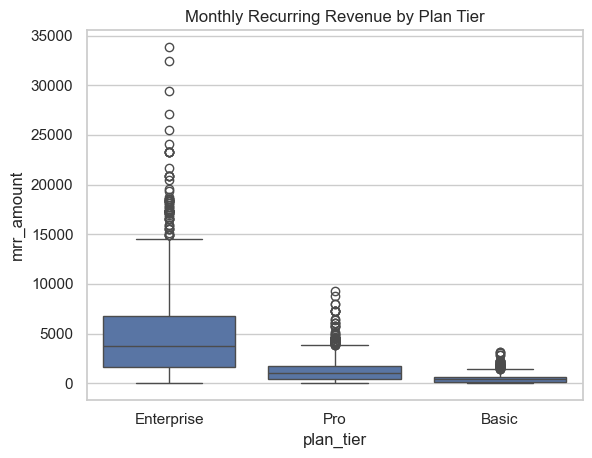

In [22]:
sns.boxplot(
    data=subscriptions,
    x="plan_tier",
    y="mrr_amount"
)
plt.title("Monthly Recurring Revenue by Plan Tier")

Text(0.5, 1.0, 'Billing Frequency by Plan Tier')

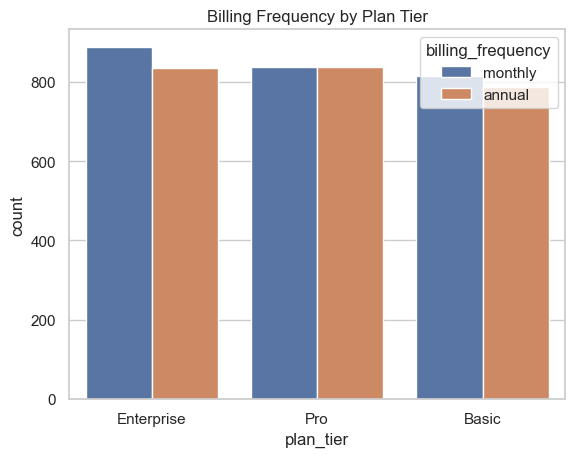

In [26]:
sns.countplot(
    data=subscriptions,
    x="plan_tier",
    hue="billing_frequency"
)
plt.title("Billing Frequency by Plan Tier")

Text(0.5, 1.0, 'Churn by Billing Frequency')

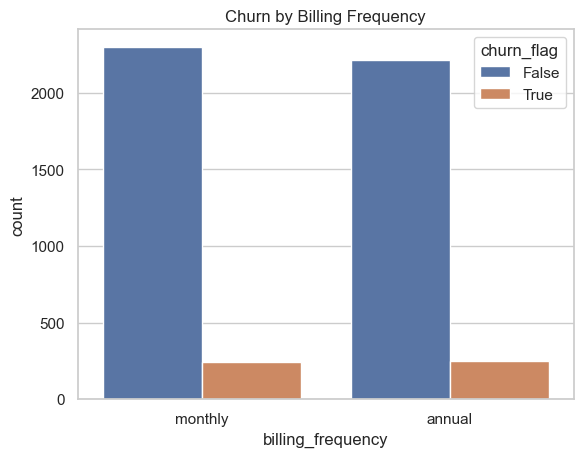

In [25]:
sns.countplot(
    data=subscriptions,
    x="billing_frequency",
    hue="churn_flag"
)
plt.title("Churn by Billing Frequency")

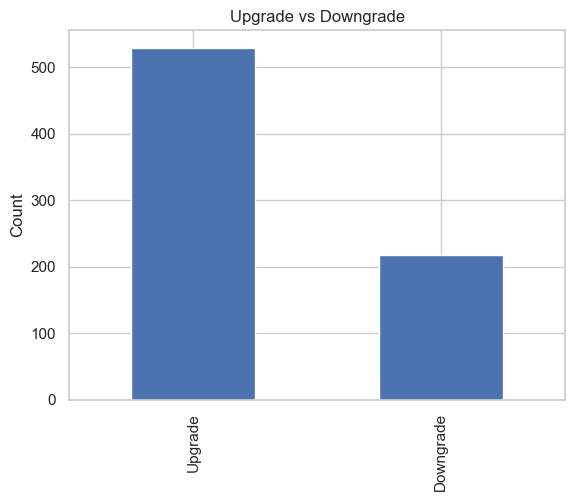

In [27]:
flags = pd.DataFrame({
    "Upgrade": [subscriptions["upgrade_flag"].sum()],
    "Downgrade": [subscriptions["downgrade_flag"].sum()]
})

flags.T.plot(kind="bar", legend=False)
plt.title("Upgrade vs Downgrade")
plt.ylabel("Count")
plt.show()

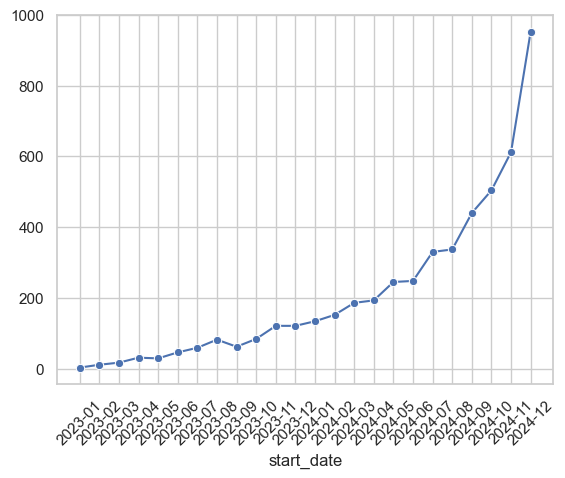

In [28]:
monthly = subscriptions.groupby(
    subscriptions["start_date"].dt.to_period("M")
).size()

monthly.index = monthly.index.astype(str)

sns.lineplot(
    x=monthly.index,
    y=monthly.values,
    marker="o"
)

plt.xticks(rotation=45)
plt.show()

### Explore Support Table

In [31]:
support = pd.read_csv(
    r'C:\PROJECTS\Financial_Operations_analytics\Data\Processed\support_cleaned.csv',
    parse_dates=["submitted_at", "closed_at"]
)

In [32]:
support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ticket_id                    2000 non-null   object        
 1   account_id                   2000 non-null   object        
 2   submitted_at                 2000 non-null   datetime64[ns]
 3   closed_at                    2000 non-null   datetime64[ns]
 4   resolution_time_hours        2000 non-null   float64       
 5   priority                     2000 non-null   object        
 6   first_response_time_minutes  2000 non-null   int64         
 7   satisfaction_score           1175 non-null   float64       
 8   escalation_flag              2000 non-null   bool          
dtypes: bool(1), datetime64[ns](2), float64(2), int64(1), object(3)
memory usage: 127.1+ KB


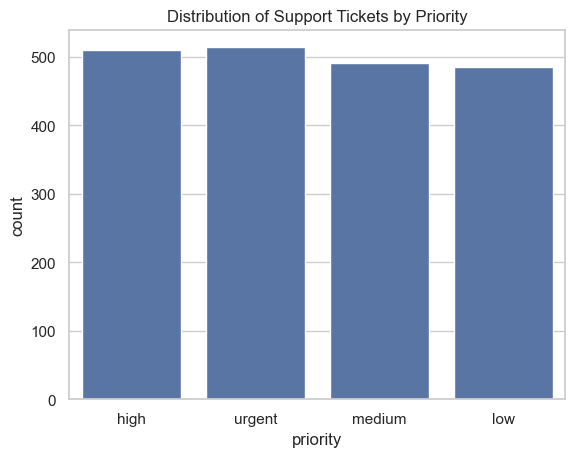

In [33]:
sns.countplot(data=support, x="priority")
plt.title("Distribution of Support Tickets by Priority")
plt.show()

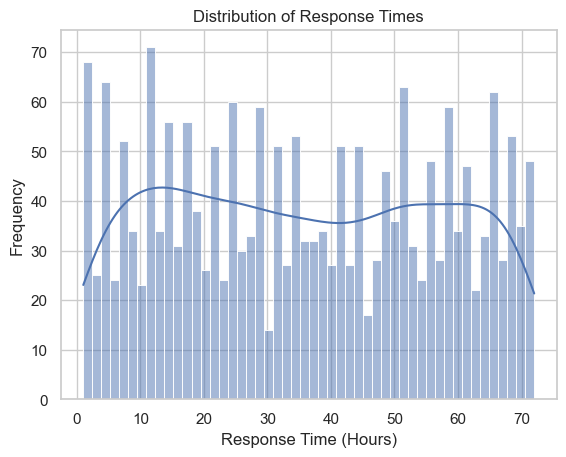

In [36]:
sns.histplot(support["resolution_time_hours"], bins=50, kde=True)
plt.title("Distribution of Response Times")
plt.xlabel("Response Time (Hours)")
plt.ylabel("Frequency")
plt.show()


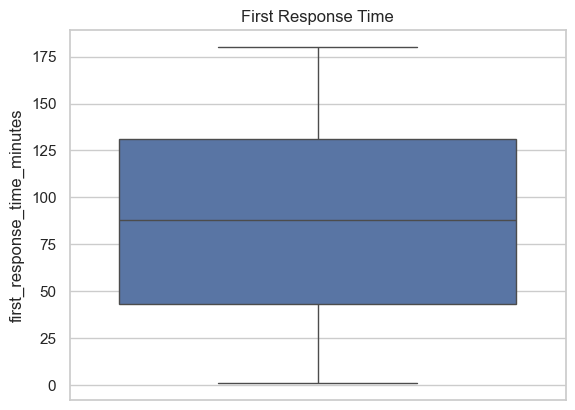

In [37]:
sns.boxplot(y=support["first_response_time_minutes"])
plt.title("First Response Time")
plt.show()

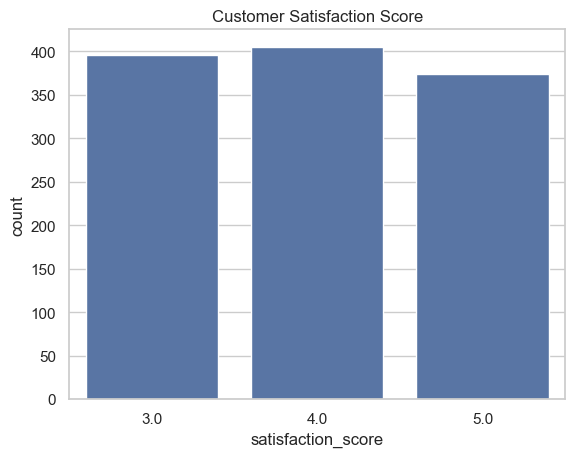

In [38]:
sns.countplot(data=support, x="satisfaction_score")
plt.title("Customer Satisfaction Score")
plt.show()

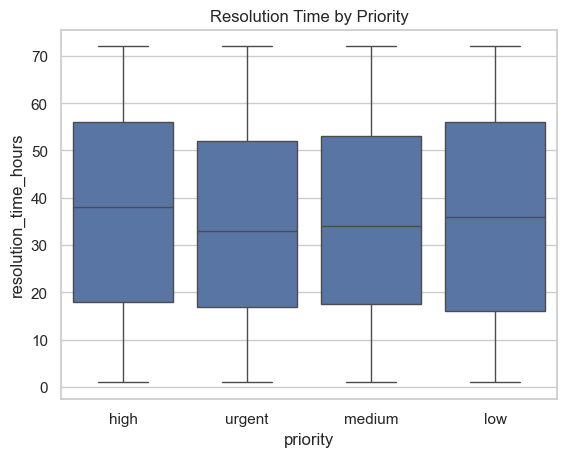

In [39]:
sns.boxplot(
    data=support,
    x="priority",
    y="resolution_time_hours"
)
plt.title("Resolution Time by Priority")
plt.show()

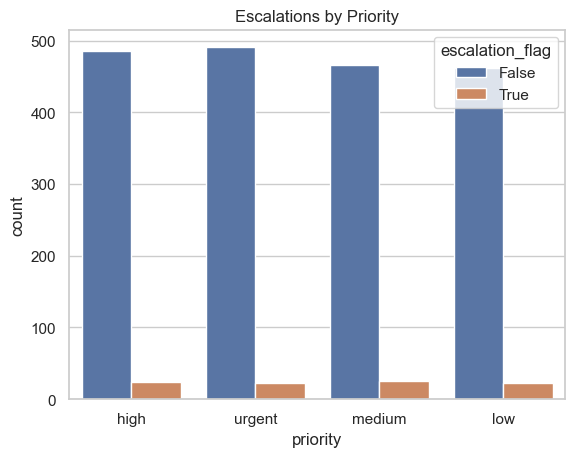

In [40]:
sns.countplot(
    data=support,
    x="priority",
    hue="escalation_flag"
)
plt.title("Escalations by Priority")
plt.show()

In [42]:
support["satisfaction_score"].isna().sum()

825

In [43]:
support["satisfaction_score"].isna().mean() * 100

41.25